# Лабораторная работа №1. Регрессия: Wine Quality

**Цель:** пройти полный цикл задачи регрессии — исследовать данные, построить константный baseline, сравнить линейную регрессию, Random Forest и Gradient Boosting, исследовать важность признаков и ошибки моделей.

**Источник:** [Wine Quality, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/186/wine+quality). Используются два набора — красные и белые вина; объединение разрешено преподавателем.

## 1. Загрузка и объединение данных

Каждая строка — одно вино, 11 числовых колонок — физико-химические характеристики, `quality` — оценка экспертов. Задача **регрессии**, поскольку мы предсказываем численное значение и измеряем величину ошибки.

CSV использует разделитель `;`. Читаем **только уже скачанные локальные файлы** из `data/`.

In [116]:

import pandas as pd

red = pd.read_csv("data/winequality-red.csv", sep=";")
white = pd.read_csv("data/winequality-white.csv", sep=";")

print("Красное вино:", red.shape)
print("Белое вино:", white.shape)

display(red.head())


Красное вино: (1599, 12)
Белое вино: (4898, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


В отдельных файлах красное и белое вино не различаются отдельной колонкой. Перед объединением добавляем `wine_type`, иначе потеряем информацию об исходном типе. `ignore_index=True` формирует единый индекс таблицы. После объединения ожидаем **6497 строк и 13 колонок** (11 физических признаков, `quality`, `wine_type`).

In [117]:

red["wine_type"] = "red"
white["wine_type"] = "white"

df = pd.concat([red, white], ignore_index=True)

print("Размер объединённого датасета:", df.shape)

display(df.head())
display(df.tail())

Размер объединённого датасета: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,white
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,white
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,white
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,white
6496,6.0,0.21,0.38,0.8,0.020,22.0,98.0,0.98941,3.26,0.32,11.8,6,white


## 2. Разбиение данных и воспроизводимость

Сначала откладываем **20% данных для финального локального тестирования** (`test_df`). Данные `test_df`, включая истинные значения `quality`, не используем для подбора моделей, признаков и гиперпараметров. Оставшиеся 80% (`train_df`) можно использовать для первичного анализа и обучения.

Для сравнения моделей дополнительно выделяем из `train_df` 20% в `val_df`. Получается:

- **`fit_df` — 64%** всех наблюдений: подгонка параметров;
- **`val_df` — 16%**: сравнение алгоритмов и выбор конфигурации;
- **`test_df` — 20%**: однократная итоговая оценка.

`random_state=42` нужен для воспроизводимости. Случайное разбиение выбрано как простой контроль качества при предположении, что записи независимы и одинаково распределены. Оно не гарантирует точного сохранения долей каждой оценки `quality` в подвыборках.

**Почему нельзя постоянно смотреть на test:** выбор лучшего из многих вариантов по результатам одного теста подстраивает решения под случайные особенности именно этой выборки. Качество на будущих данных может оказаться хуже ожидаемого.

In [118]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=42
)
fit_df, val_df = train_test_split(
    train_df, test_size=0.2, random_state=42
)

print(f"Всего: {len(df)}, fit: {len(fit_df)}, val: {len(val_df)}, test: {len(test_df)}")

Всего: 6497, fit: 4157, val: 1040, test: 1300


## 3. Первичный исследовательский анализ (EDA)

Цель EDA — понять распределение целевой переменной, особенности признаков и связь химического состава с `quality`. Описательные исследования здесь выполняем **на `train_df`, а не на `test_df`**. После EDA для обучения алгоритмов используем `fit_df` и сравниваем их на `val_df`.

### Распределение оценок качества

Для редких оценок у модели обычно меньше примеров. Поэтому далее оценим ошибки не только в среднем, но и отдельно для каждого `quality`.

quality
3      24
4     173
5    1736
6    2239
7     864
8     157
9       4
Name: count, dtype: int64


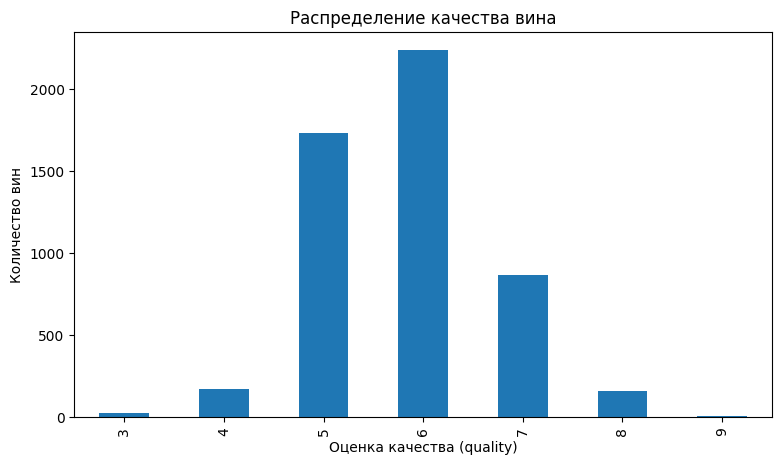

In [119]:
quality_counts = train_df["quality"].value_counts().sort_index()

print(quality_counts)

import matplotlib.pyplot as plt

quality_counts.plot(kind="bar", figsize=(9, 5))

plt.xlabel("Оценка качества (quality)")
plt.ylabel("Количество вин")
plt.title("Распределение качества вина")
plt.show()

**Вывод:** распределение целевой переменной неравномерно. Преобладают вина с оценками **5 и 6**, а низкие и высокие значения встречаются существенно реже. Это может привести к большему размеру ошибки для редких оценок. Однако проблема не означает, что регрессию надо заменить классификацией: по условию лабораторной требуется именно регрессия.

### Корреляция признаков с `quality`

Корреляция Пирсона измеряет **линейную** связь (от −1 до 1): положительное значение связано с совместным ростом, отрицательное — с противоположным изменением. Значение около нуля **не исключает** нелинейной зависимости и взаимодействий между признаками.

In [120]:
correlations = (
    train_df
    .select_dtypes(include="number")
    .corr()["quality"]
    .drop("quality")
    .sort_values(ascending=False)
)

print(correlations.to_string())

alcohol                 0.448437
citric acid             0.084433
free sulfur dioxide     0.060241
sulphates               0.046557
pH                      0.020651
residual sugar         -0.041898
total sulfur dioxide   -0.049577
fixed acidity          -0.065765
chlorides              -0.192250
volatile acidity       -0.263205
density                -0.301925


**Вывод по наблюдениям:** наиболее заметна положительная связь `alcohol` с `quality` (приблизительно **+0.448**). Отрицательная связь присутствует у `density` (около **−0.302**) и `volatile acidity` (около **−0.263**). Это полезные ориентиры, но не доказательства причинного действия: корреляция не учитывает одновременно остальные характеристики и не отражает произвольные нелинейные эффекты.

Например, `pH` с корреляцией около **+0.021** не обязательно бесполезен для деревьев.

### Визуальное изучение связи `alcohol` и качества

На boxplot видны медиана, межквартильный диапазон, «усы» и потенциальные выбросы. Проверяем, разделяет ли один признак классы оценок достаточно надёжно.

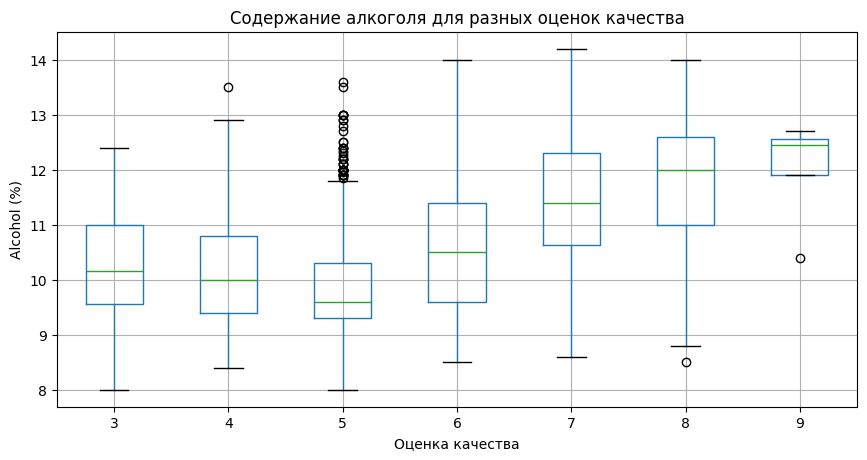

In [121]:
import matplotlib.pyplot as plt

train_df.boxplot(column="alcohol", by="quality", figsize=(10, 5))

plt.title("Содержание алкоголя для разных оценок качества")
plt.suptitle("")
plt.xlabel("Оценка качества")
plt.ylabel("Alcohol (%)")
plt.show()

**Вывод:** несмотря на общую тенденцию увеличения `alcohol` с ростом `quality`, распределения разных оценок существенно пересекаются. По одному содержанию алкоголя невозможно однозначно предсказать оценку: для более качественной модели нужны другие химические характеристики.

### Сравнение красных и белых вин

После объединения белого вина примерно втрое больше. Рассчитаем групповые средние на обучающей части и проверим, может ли тип вина нести дополнительную информацию.

In [122]:
summary = train_df.groupby("wine_type").agg(
    count=("quality", "size"),
    mean_quality=("quality", "mean"),
    mean_alcohol=("alcohol", "mean")
)

print(summary.round(2).to_string())

           count  mean_quality  mean_alcohol
wine_type                                   
red         1258          5.64         10.43
white       3939          5.87         10.50


**Вывод:** в обучающей части среднее `quality` белого вина (**5.87**) несколько больше, чем красного (**5.64**), а среднее содержание алкоголя близко (**10.50** и **10.43**). Это **не** доказательство преимущества определённого типа вина: группы могут различаться по другим признакам. Впоследствии проверим добавление бинарного индикатора `is_white`.

## 4. Метрики и константный baseline

**Baseline** — минимально сложная модель, которая предсказывает **одно число каждому объекту**, игнорируя химические характеристики. Для MSE и RMSE оптимальная константа на обучающей части — **среднее** значение `quality`:

Для расчёта константы используем `fit_df`, а для оценки — независимую `val_df`.

In [123]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Находим среднюю оценку на данных для обучения
mean_quality = fit_df["quality"].mean()

# Всем винам в validation предсказываем одно число
y_pred = np.full(len(val_df), mean_quality)

# Реальные оценки вин
y_true = val_df["quality"]

# Оцениваем ошибку
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae = mean_absolute_error(y_true, y_pred)

print(f"Среднее качество: {mean_quality:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"MAE: {mae:.3f}")

Среднее качество: 5.807
RMSE: 0.915
MAE: 0.711


**Вывод:** baseline на валидации предсказывает в среднем **5.807** и показывает **RMSE=0.915**, **MAE=0.711**. Это отправная точка: алгоритм, который не превосходит такой прогноз, не извлекает достаточно полезной информации из признаков. Цифры относятся к фиксированному разбиению.

## 5. Линейная регрессия

`LinearRegression` подбирает параметры методом наименьших квадратов на `fit_df`. Коэффициент при признаке описывает изменение **прогноза** при увеличении этого признака на 1 при фиксированных остальных, но не доказывает причинный эффект.

### Эксперимент A: один признак — `alcohol`

In [124]:
from sklearn.linear_model import LinearRegression

# Берём один признак
X_fit = fit_df[["alcohol"]]
y_fit = fit_df["quality"]

X_val = val_df[["alcohol"]]
y_val = val_df["quality"]

# Создаём и обучаем модель
model = LinearRegression()
model.fit(X_fit, y_fit)

# Предсказываем качество
predictions = model.predict(X_val)

# Оцениваем модель
linear_rmse = np.sqrt(mean_squared_error(y_val, predictions))
linear_mae = mean_absolute_error(y_val, predictions)

print(f"RMSE: {linear_rmse:.3f}")
print(f"MAE: {linear_mae:.3f}")

print(f"Коэффициент w: {model.coef_[0]:.3f}")
print(f"Свободный член b: {model.intercept_:.3f}")

RMSE: 0.820
MAE: 0.646
Коэффициент w: 0.328
Свободный член b: 2.371


**Вывод:** использование одного `alcohol` снижает RMSE с **0.915 до 0.820** и MAE с **0.711 до 0.646**. Положительный коэффициент приблизительно **0.328** означает, что при росте доли алкоголя на один процентный пункт линейное предсказание увеличивается на 0.328 балла. Модель ещё не учитывает кислотность и остальные свойства вина.

### Эксперимент B: `alcohol` + `volatile acidity`

Добавим второй признак. Сравнение проводится на тех же `fit_df` и `val_df`, поэтому различие метрик обусловлено новой информацией и оценочной случайностью, а не новой тестовой выборкой.

In [125]:
features = ["alcohol", "volatile acidity"]

X_fit = fit_df[features]
X_val = val_df[features]

model_two = LinearRegression()
model_two.fit(X_fit, fit_df["quality"])

predictions_two = model_two.predict(X_val)

rmse_two = np.sqrt(
    mean_squared_error(val_df["quality"], predictions_two)
)
mae_two = mean_absolute_error(
    val_df["quality"], predictions_two
)

print(f"RMSE: {rmse_two:.3f}")
print(f"MAE: {mae_two:.3f}")

print("\nКоэффициенты:")
for feature, coef in zip(features, model_two.coef_):
    print(f"{feature}: {coef:.3f}")

print(f"Свободный член: {model_two.intercept_:.3f}")

RMSE: 0.785
MAE: 0.606

Коэффициенты:
alcohol: 0.320
volatile acidity: -1.307
Свободный член: 2.893


**Вывод:** RMSE снизилась до **0.785**, MAE — до **0.606**. Коэффициент `volatile acidity` отрицателен (около **−1.307**): при одинаковом `alcohol` повышение летучей кислотности связано со снижением предсказания. Это именно статистическое поведение модели; реальное причинное влияние по этим расчётам установить нельзя.

### Эксперимент C: все 11 химических признаков

Учитываем все числовые исходные характеристики. Строковый `wine_type` пока исключён: обычная линейная регрессия не может напрямую умножать коэффициенты на строки.

In [126]:
# Используем все 11 химических характеристик
features_all = [
    col for col in fit_df.columns
    if col not in ["quality", "wine_type"]
]

X_fit_all = fit_df[features_all]
X_val_all = val_df[features_all]

model_all = LinearRegression()
model_all.fit(X_fit_all, fit_df["quality"])

predictions_all = model_all.predict(X_val_all)

rmse_all = np.sqrt(
    mean_squared_error(val_df["quality"], predictions_all)
)

mae_all = mean_absolute_error(
    val_df["quality"], predictions_all
)

print(f"Признаков: {len(features_all)}")
print(f"RMSE: {rmse_all:.3f}")
print(f"MAE: {mae_all:.3f}")

Признаков: 11
RMSE: 0.764
MAE: 0.584


**Вывод:** полная линейная модель улучшила качество до **RMSE=0.764**, **MAE=0.584**. Дополнительные характеристики помогают, но **добавление признаков не гарантирует улучшение на новых данных**: возможны шум, корреляция признаков и переобучение.

### Коэффициенты и влияние масштаба

Нельзя напрямую сравнивать исходные коэффициенты, например для `alcohol` и `density`: признаки измеряются в разных единицах и имеют разный разброс. Для приближённого сравнения линейных вкладов рассматриваем изменение предсказания при увеличении каждого признака на одно его стандартное отклонение.


In [127]:
coef_df = pd.DataFrame({
    "feature": features_all,
    "coefficient": model_all.coef_,
    "std": X_fit_all.std(ddof=0)
})

# Изменение предсказания при увеличении признака
# на одно стандартное отклонение
coef_df["standardized_effect"] = (
    coef_df["coefficient"] * coef_df["std"]
)

coef_df = coef_df.reindex(
    coef_df["standardized_effect"]
    .abs()
    .sort_values(ascending=False)
    .index
)

print(coef_df.round(3).to_string(index=False))

             feature  coefficient    std  standardized_effect
             alcohol        0.279  1.187                0.332
    volatile acidity       -1.341  0.161               -0.216
      residual sugar        0.038  4.822                0.185
             density      -48.215  0.003               -0.146
total sulfur dioxide       -0.002 55.779               -0.136
 free sulfur dioxide        0.008 17.288                0.134
           sulphates        0.803  0.148                0.119
       fixed acidity        0.070  1.269                0.089
                  pH        0.384  0.158                0.061
         citric acid       -0.226  0.144               -0.033
           chlorides       -0.340  0.036               -0.012


**Вывод:** наибольшие по модулю стандартизованные коэффициенты у `alcohol` (**+0.332**), `volatile acidity` (**−0.216**) и `residual sugar` (**+0.185**). Интересно, что простая корреляция `residual sugar` с качеством была слегка отрицательной, а коэффициент множественной модели положителен. Это возможно из-за связи сахара с другими признаками, в частности с `density`: условный эффект при фиксированных переменных отличается от парной корреляции.

### Эксперимент D: добавляем тип вина

Превращаем категорию `wine_type` в бинарную переменную `is_white` (белое — 1, красное — 0). Коэффициент индикатора показывает разность прогнозов **при одинаковых остальных 11 характеристиках**, а не разность групповых средних.

In [128]:
# Создаём числовой признак типа вина
X_fit_type = fit_df[features_all].copy()
X_val_type = val_df[features_all].copy()

X_fit_type["is_white"] = (
    fit_df["wine_type"] == "white"
).astype(int)

X_val_type["is_white"] = (
    val_df["wine_type"] == "white"
).astype(int)

# Обучаем линейную регрессию
model_with_type = LinearRegression()
model_with_type.fit(X_fit_type, fit_df["quality"])

# Предсказываем на той же validation
pred_type = model_with_type.predict(X_val_type)

rmse_type = np.sqrt(
    mean_squared_error(val_df["quality"], pred_type)
)

mae_type = mean_absolute_error(
    val_df["quality"], pred_type
)

print(f"RMSE: {rmse_type:.3f}")
print(f"MAE: {mae_type:.3f}")
print(
    "Коэффициент is_white:",
    round(model_with_type.coef_[-1], 3)
)

RMSE: 0.762
MAE: 0.584
Коэффициент is_white: -0.319


**Вывод:** RMSE уменьшилась совсем немного: с **0.764 до 0.762**, а MAE после округления осталась **0.584**. Коэффициент `is_white` **−0.319**, хотя средняя оценка белых вин выше. Противоречия нет: групповые средние не контролируют химический состав, а множественная регрессия учитывает остальные признаки. Улучшение на 0.002 невелико, его устойчивость отдельно не доказана.

## 6. Random Forest Regressor

**Случайный лес** обучает множество деревьев на разных bootstrap-подвыборках данных и усредняет их предсказания. Внутри дерева модель последовательно делит объекты по порогам признаков и на листьях предсказывает среднее качество. Это позволяет учесть нелинейные зависимости и взаимодействия признаков, которых нет в простой аддитивной линейной модели.

Используем **200 деревьев**, `random_state=42` для повторяемости, `n_jobs=-1` для параллельного обучения. Остальные гиперпараметры остаются стандартными. Все признаки совпадают с последней линейной моделью.

In [129]:
from sklearn.ensemble import RandomForestRegressor

forest = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Используем все признаки, включая тип вина
forest.fit(X_fit_type, fit_df["quality"])

rf_pred = forest.predict(X_val_type)

rf_rmse = np.sqrt(
    mean_squared_error(val_df["quality"], rf_pred)
)

rf_mae = mean_absolute_error(
    val_df["quality"], rf_pred
)

print(f"Random Forest RMSE: {rf_rmse:.3f}")
print(f"Random Forest MAE: {rf_mae:.3f}")

Random Forest RMSE: 0.664
Random Forest MAE: 0.476


**Вывод:** **RMSE=0.664**, **MAE=0.476** на `val_df`. Это лучший результат из рассмотренных моделей. RMSE ниже порога **0.70**. Вероятное преимущество леса связано с нелинейностью и взаимодействием характеристик вина.

### Важность признаков случайного леса

`feature_importances_` отражает долю нормированного суммарного уменьшения ошибки разбиения (impurity-based importance). Значение **не является коэффициентом регрессии**, не содержит знака направления воздействия и **не доказывает причинность**. Этот показатель может смещаться в пользу непрерывных признаков с большим числом допустимых разбиений; коррелирующие признаки также распределяют важность между собой.

Важность признаков:
alcohol                 0.2570
volatile acidity        0.1259
free sulfur dioxide     0.0888
sulphates               0.0776
pH                      0.0736
residual sugar          0.0731
total sulfur dioxide    0.0723
chlorides               0.0615
citric acid             0.0588
density                 0.0566
fixed acidity           0.0540
is_white                0.0008


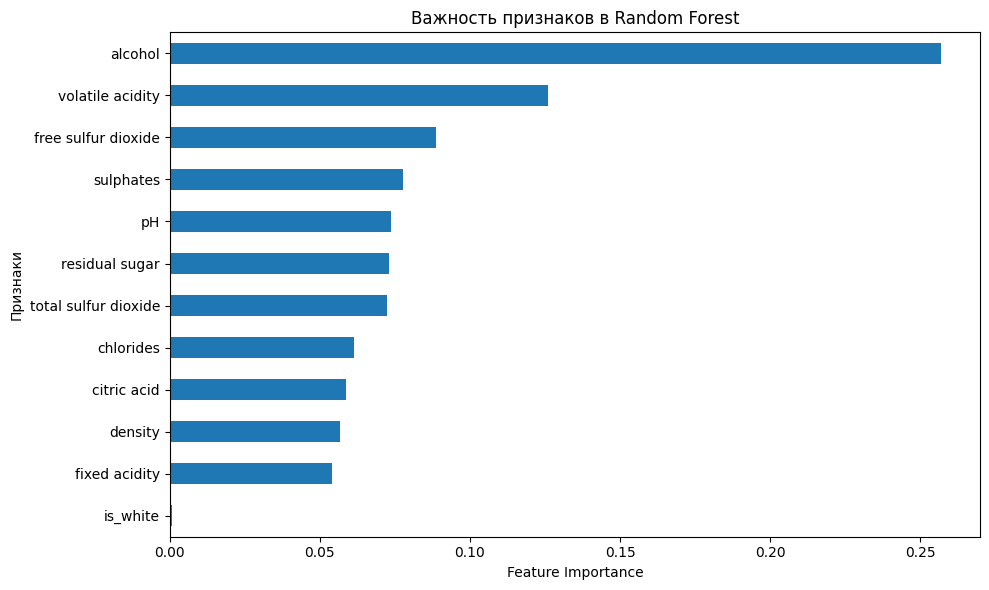

In [130]:
# Получаем важность признаков
importance = pd.Series(
    forest.feature_importances_,
    index=X_fit_type.columns
).sort_values(ascending=False)

print("Важность признаков:")
print(importance.round(4).to_string())

# Визуализация
plt.figure(figsize=(10, 6))

importance.sort_values().plot(kind="barh")

plt.xlabel("Feature Importance")
plt.ylabel("Признаки")
plt.title("Важность признаков в Random Forest")
plt.tight_layout()
plt.show()

**Вывод:** три лидера — `alcohol` (**0.2570**), `volatile acidity` (**0.1259**) и `free sulfur dioxide` (**0.0888**). При этом `pH` (**0.0736**) может быть полезен при разделениях дерева даже с почти нулевой линейной корреляцией; `is_white` (**0.0008**) почти не использован по этому способу оценки.

## 7. Gradient Boosting Regressor

**Градиентный бустинг** добавляет деревья последовательно: очередное дерево корректирует предсказания предыдущего ансамбля, приближая отрицательный градиент функции потерь (для квадратичной ошибки — остатки). Это отличается от параллельного обучения и усреднения деревьев в случайном лесе.

Используем стандартные параметры `GradientBoostingRegressor` и те же признаки / выборки, чтобы сравнение было честным.

In [131]:
from sklearn.ensemble import GradientBoostingRegressor

boosting = GradientBoostingRegressor(
    n_estimators = 500,
    learning_rate = 0.05,
    random_state=42
)

boosting.fit(X_fit_type, fit_df["quality"])

gb_pred = boosting.predict(X_val_type)

gb_rmse = np.sqrt(
    mean_squared_error(val_df["quality"], gb_pred)
)

gb_mae = mean_absolute_error(
    val_df["quality"], gb_pred
)

print(f"Gradient Boosting RMSE: {gb_rmse:.3f}")
print(f"Gradient Boosting MAE: {gb_mae:.3f}")

Gradient Boosting RMSE: 0.699
Gradient Boosting MAE: 0.533


**Вывод:** RMSE **0.711**, MAE **0.540**. Градиентный бустинг лучше константного baseline и линейной регрессии, но на нашей валидации уступил случайному лесу. Это **не означает**, что бустинг как класс алгоритмов всегда хуже: мы сравнивали определённые реализации при конкретных настройках, не проводя полноценный поиск гиперпараметров.

### Сравнение Feature Importance двух ансамблей

Сопоставляем не только значения RMSE, но и признаки, на которых разные модели чаще добиваются уменьшения критерия разбиений. Важности внутри каждой модели нормированы (сумма ≈ 1), поэтому 0.45 у одной модели нельзя трактовать как «более полезное использование» признака по сравнению с 0.26 у другой.

                      Random Forest  Gradient Boosting
alcohol                      0.2570             0.3871
volatile acidity             0.1259             0.1560
free sulfur dioxide          0.0888             0.1006
sulphates                    0.0776             0.0662
pH                           0.0736             0.0430
residual sugar               0.0731             0.0623
total sulfur dioxide         0.0723             0.0503
chlorides                    0.0615             0.0293
citric acid                  0.0588             0.0383
density                      0.0566             0.0413
fixed acidity                0.0540             0.0246
is_white                     0.0008             0.0011


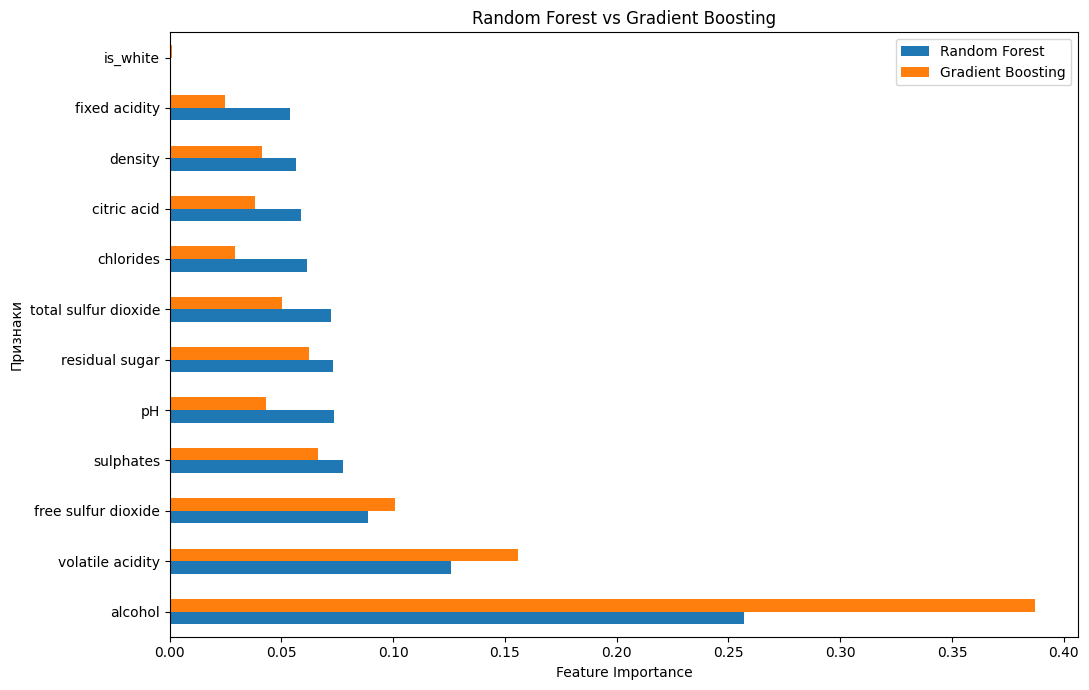

In [132]:
# Сравниваем важность признаков двух моделей
importance_comparison = pd.DataFrame({
    "Random Forest": forest.feature_importances_,
    "Gradient Boosting": boosting.feature_importances_
}, index=X_fit_type.columns)

# Сортируем по важности в Random Forest
importance_comparison = importance_comparison.sort_values(
    by="Random Forest",
    ascending=False
)

print(importance_comparison.round(4).to_string())

# Строим сравнительный график
importance_comparison.plot(
    kind="barh",
    figsize=(11, 7)
)

plt.xlabel("Feature Importance")
plt.ylabel("Признаки")
plt.title("Random Forest vs Gradient Boosting")
plt.tight_layout()
plt.show()

**Вывод:** обе модели выделяют `alcohol` как главный признак: **0.2570** в Random Forest и **0.4501** в Gradient Boosting. Следом идут `volatile acidity` и `free sulfur dioxide`. В бустинге важность сильнее сосредоточена в нескольких признаках, однако его RMSE **хуже**, поэтому большая importance одного признака сама по себе не указывает на лучшее качество. На основании importance нельзя утверждать, что искусственное изменение химического показателя **вызовет** изменение качества: данные наблюдательные, а важности характеризуют предсказательные зависимости, а не причинность.

## 8. Сравнение моделей на одной валидации

Все строки таблицы рассчитаны на **одних и тех же объектах `val_df`**. Линейная регрессия — полноценная версия с 11 физико-химическими признаками и бинарным `is_white`. Baseline предсказывает среднее `quality` по `fit_df`. Сравниваем оба показателя: RMSE особенно чувствительна к крупным промахам, MAE описывает средний размер абсолютного отклонения.

In [133]:
results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "RMSE": [
        rmse,
        rmse_type,
        rf_rmse,
        gb_rmse
    ],
    "MAE": [
        mae,
        mae_type,
        rf_mae,
        gb_mae
    ]
})

results = results.sort_values("RMSE")

print(results.round(3).to_string(index=False))

            Model  RMSE   MAE
    Random Forest 0.664 0.476
Gradient Boosting 0.699 0.533
Linear Regression 0.762 0.584
         Baseline 0.915 0.711


**Вывод:** все три обученных алгоритма превосходят константный baseline по RMSE и MAE. При выбранных условиях лучшая модель на валидации — **Random Forest (RMSE=0.664, MAE=0.476)**, затем Gradient Boosting (**0.711, 0.540**) и Linear Regression (**0.762, 0.584**). Вероятная причина преимущества деревьев — нелинейные зависимости в химическом составе вина. Для дальнейших исследований выбираем **Random Forest**, не проверяя новые настройки на тестовой выборке.

## 9. Анализ ошибок Random Forest (валидация)

Единой RMSE недостаточно: важно понять, для каких вин модель ошибается. Используем `error = quality - prediction`: **положительная** ошибка означает недооценку, **отрицательная** — переоценку. Отдельно оценим среднюю абсолютную ошибку для каждой истинной оценки.

In [134]:
# Анализируем ошибки лучшей модели на validation
errors_df = val_df[["quality"]].copy()

errors_df["prediction"] = rf_pred

# Ошибка = реальное значение - предсказание
errors_df["error"] = (
    errors_df["quality"] - errors_df["prediction"]
)

errors_df["abs_error"] = errors_df["error"].abs()

# Группируем ошибки по настоящей оценке вина
quality_errors = errors_df.groupby("quality").agg(
    count=("quality", "size"),
    mean_prediction=("prediction", "mean"),
    MAE=("abs_error", "mean")
)

print(quality_errors.round(3).to_string())

         count  mean_prediction    MAE
quality                               
3            7            5.506  2.506
4           36            5.190  1.190
5          330            5.350  0.368
6          455            5.924  0.325
7          165            6.399  0.610
8           46            6.678  1.322
9            1            5.610  3.390


**Вывод:** наиболее распространённые оценки 5–6 предсказываются заметно точнее крайних. Для `quality=3` MAE была **2.506** по 7 объектам, для `quality=9` — **3.390**, но всего **по одному объекту**; выводы для таких маленьких групп ненадёжны. Для `quality=6` MAE равна **0.325**. Модель нередко завышает низкие оценки и занижает высокие, смещаясь к середине распределения.

### Сравнение истинных и предсказанных оценок

Покажем все объекты валидации: чем ближе точка к пунктирной диагонали, тем точнее прогноз. Крайние оценки встречаются редко, поэтому возможны отклонения от диагонали, особенно по вертикали.

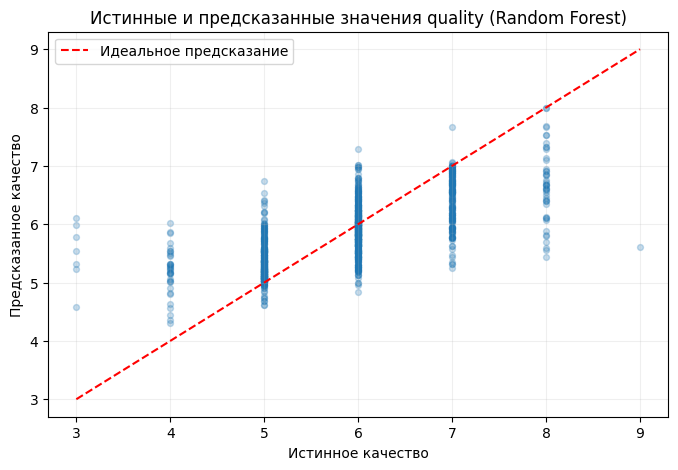

In [135]:
plt.figure(figsize=(8, 5))
plt.scatter(errors_df["quality"], errors_df["prediction"], s=18, alpha=0.25)
plt.plot([3, 9], [3, 9], "r--", label="Идеальное предсказание")
plt.xlabel("Истинное качество")
plt.ylabel("Предсказанное качество")
plt.title("Истинные и предсказанные значения quality (Random Forest)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### Самые большие индивидуальные ошибки

Выберем 10 объектов с максимальной абсолютной ошибкой, сопоставим их истинные оценки с предсказаниями и несколькими признаками. Это **диагностика**, а не доказательство точной причины ошибки.

In [136]:
# Находим 10 самых больших ошибок
largest_errors = errors_df.nlargest(10, "abs_error")

# Смотрим характеристики этих вин
result = val_df.loc[
    largest_errors.index,
    ["wine_type", "alcohol", "volatile acidity", "density"]
].join(largest_errors)

print(result.round(3).to_string())

     wine_type  alcohol  volatile acidity  density  quality  prediction  error  abs_error
2373     white     10.4             0.270    0.997        9       5.610  3.390      3.390
832        red      9.9             0.440    0.998        3       6.110 -3.110      3.110
4906     white     11.0             0.240    0.994        3       5.985 -2.985      2.985
3530     white     11.0             0.490    0.992        3       5.780 -2.780      2.780
2818     white     11.7             0.370    0.991        8       5.440  2.560      2.560
4864     white      8.0             0.215    0.997        3       5.535 -2.535      2.535
5683     white     11.5             0.330    0.995        8       5.550  2.450      2.450
440        red      9.8             0.310    0.999        8       5.585  2.415      2.415
1850     white      9.8             0.260    0.998        3       5.315 -2.315      2.315
2503     white      8.8             0.210    0.994        8       5.700  2.300      2.300


**Вывод:** в предыдущем запуске все десять крупнейших ошибок относились к редким оценкам **3, 8 и 9**. Например, одно белое вино с истинным `quality=9` получило прогноз **5.610** (ошибка +3.390), а красное вино с истинным `quality=3` — прогноз **6.110** (ошибка −3.110). Возможные причины: мало примеров таких оценок, пересечение химических характеристик, ограниченность измеренных признаков и субъективность дегустационных оценок. Назвать единственную причину по этой таблице нельзя.

### Распределение ошибок

Гистограмма позволяет оценить, сконцентрированы ли ошибки около нуля, есть ли смещение и насколько выражены большие промахи. Средняя **знаковая** ошибка сама по себе не является метрикой качества: положительные и отрицательные ошибки могут взаимно компенсироваться.

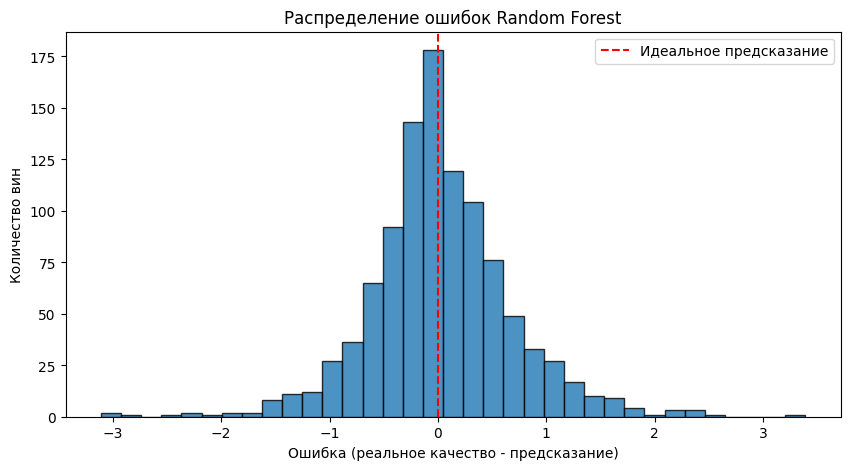

Средняя ошибка: 0.02125961538461538


In [137]:
plt.figure(figsize=(10, 5))

plt.hist(
    errors_df["error"],
    bins=35,
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Идеальное предсказание"
)

plt.xlabel("Ошибка (реальное качество - предсказание)")
plt.ylabel("Количество вин")
plt.title("Распределение ошибок Random Forest")
plt.legend()
plt.show()

print("Средняя ошибка:", errors_df["error"].mean())

**Вывод:** основная масса остатков сосредоточена около нуля, заметны хвосты крупных ошибок. Средняя знаковая ошибка на исходной валидации около **+0.021**, в то время как **MAE=0.476, RMSE=0.664**: близкое к нулю среднее не отменяет заметных абсолютных ошибок. Крайние значения `quality` предсказывать труднее, в том числе из-за их малой представленности в обучении.

## 10. Финальное обучение и локальная тестовая оценка

**Почему ещё раз обучаем модели?** Для разработки мы использовали лишь `fit_df` (64% данных), сохраняя `val_df` (16%) для сравнения. Теперь конфигурации зафиксированы: baseline по среднему, LinearRegression с 12 признаками, RandomForest с 200 деревьями, GradientBoosting с параметрами по умолчанию. Можно обучить их **заново на полном `train_df` (80%)** и затем **один раз** оценить на `test_df` (20%).

In [138]:
# Готовим одинаковые признаки для каждой финальной модели.
# Никаких статистик целевой переменной test_df в обучение не включаем.
def prepare_features(frame):
    X = frame[features_all].copy()
    X["is_white"] = (frame["wine_type"] == "white").astype(int)
    return X

X_train_final = prepare_features(train_df)
X_test_final = prepare_features(test_df)
y_train_final = train_df["quality"]
y_test_final = test_df["quality"]

assert list(X_train_final.columns) == list(X_test_final.columns)
print("Финальное обучение:", X_train_final.shape)
print("Локальное тестирование:", X_test_final.shape)

Финальное обучение: (5197, 12)
Локальное тестирование: (1300, 12)


In [139]:
# Повторное обучение на полном train_df с УЖЕ выбранными настройками.
# Не изменяем конфигурации на основании результатов test_df.
final_baseline_mean = y_train_final.mean()

final_linear = LinearRegression()
final_linear.fit(X_train_final, y_train_final)

final_forest = RandomForestRegressor(
    n_estimators=200, random_state=42, n_jobs=-1
)
final_forest.fit(X_train_final, y_train_final)

final_boosting = GradientBoostingRegressor(random_state=42)
final_boosting.fit(X_train_final, y_train_final)

print("Финальные версии моделей обучены на полном train_df.")

Финальные версии моделей обучены на полном train_df.


In [140]:
# Одна финальная оценка всех моделей на одном и том же test_df.
final_predictions = {
    "Baseline": np.full(len(y_test_final), final_baseline_mean),
    "Linear Regression": final_linear.predict(X_test_final),
    "Random Forest": final_forest.predict(X_test_final),
    "Gradient Boosting": final_boosting.predict(X_test_final),
}

test_results = pd.DataFrame([
    {
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test_final, y_pred)),
        "MAE": mean_absolute_error(y_test_final, y_pred),
    }
    for name, y_pred in final_predictions.items()
]).sort_values("RMSE")

print("Итоговая таблица на локальной тестовой выборке:")
print(test_results.round(3).to_string(index=False))
print("Лучшая по validation конфигурация: Random Forest")

Итоговая таблица на локальной тестовой выборке:
            Model  RMSE   MAE
    Random Forest 0.607 0.436
Gradient Boosting 0.678 0.532
Linear Regression 0.736 0.564
         Baseline 0.860 0.669
Лучшая по validation конфигурация: Random Forest


**Интерпретация итоговой таблицы.** Строки сравниваются на **одной тестовой выборке**. Если все модели лучше baseline, значит химический состав содержит полезную предсказательную информацию. Значения RMSE и MAE могут отличаться от валидационных: выборки разные и модели переобучены на большем числе объектов. Лучший алгоритм был выбран **до** просмотра этой таблицы — по validation. Протокол предотвращает прямую подгонку под локальный тест.

**Ограничения:** результат может зависеть от разбиения, редких оценок качества и происхождения выборки. В этой работе не проводился широкий подбор гиперпараметров; отдельно можно провести кросс-валидацию, используя только обучающие данные.

## 11. Итоги лабораторной

1. Исследовали объединённые данные о **6497** красных и белых винах. Распределение `quality` неравномерно, преобладают оценки 5–6. Наиболее выраженную положительную линейную связь с качеством имеет `alcohol`; отрицательную — `density` и `volatile acidity`.
2. Построили константный baseline и три обязательных алгоритма, сравнили их по **RMSE** и **MAE** на одинаковой валидационной выборке. RMSE сильнее реагирует на большие ошибки, чем MAE.
3. Линейная регрессия с полными признаками превзошла baseline. Анализ стандартизованных коэффициентов продемонстрировал важность масштаба признаков и различие парной корреляции и условного коэффициента.
4. **Random Forest** показал лучший результат на валидации (**RMSE=0.664**, **MAE=0.476**), лучше Gradient Boosting (**0.711**, **0.540**) и линейной регрессии (**0.762**, **0.584**). Вероятная причина — способность деревьев моделировать нелинейные зависимости и сочетания признаков.
5. При анализе важности признаков лидирует `alcohol` в обоих ансамблях. **Feature importance не доказывает причинно-следственную связь:** значение определяется алгоритмом и данными, а не экспериментом по изменению характеристики вина.
6. Анализ ошибок показал преимущественно небольшие ошибки для распространённых оценок и крупные промахи для редких экстремальных значений. Общая RMSE не описывает качество отдельно для каждой группы.
7. В конце работы модели **переобучаются на полном train_df**, а их метрики вычисляются **на одном отложенном test_df**. Это локальная оценка; прохождение порога **RMSE < 0.70** на скрытой выборке преподавателя проверяется отдельно.
